# Advertised Vehicle Price Model Output Review

This notebook reads completed runs from the project MODEL_OUTPUT directory. It summarizes held-out test metrics, checks run metadata and saved model files, and reviews SHAP global and row-level explanations when available.

Set the run parameters below, then run top to bottom. The notebook does not train models or change run artifacts.

Each run contains `metrics.csv` and `run_metadata.json`. Boosted-tree models may also contain SHAP artifacts. Random Forest is interpreted with impurity-based feature importance; regression models are interpreted with their fitted coefficients.
 
Current runs include all advertised listings, with `is_new` retained as a predictor and reported error segment. The runner compares exactly two feature sets: listing-only `base` and `enriched`. Four decoded cohort fields remain separate in receipts but are not base predictors. Enriched includes vPIC, complaint/recall, and safety summaries. Evaluation can hold out complete year/make/model families or hold out VINs within known families. Reports include decoded year, make, and year-by-make test errors. Test metrics describe historical advertised listings, not realized sale prices or verified future-market performance.

In [44]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

def find_project_root(start=None):
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "MODELS" / "Price_ML_Models.py").is_file():
            return candidate
    raise FileNotFoundError("Run the notebook from inside E:/DataScience_Capstone_Cars.")

PROJECT_ROOT = find_project_root()
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from MODELS.Price_ML_Models import compatible_run_metadata, MODEL_FEATURE_SETS

MODEL_OUTPUT_DIR = PROJECT_ROOT / "MODEL_OUTPUT"
MODEL_TYPE = "base"   # Primary single-run diagnostics below.
COMPARISON_MODEL_TYPES = ["base", "enriched"]
RUN_PATH = None       # Optional explicit primary run folder.
RUN_PATHS = {}        # Optional {model_type: run folder}; otherwise newest completed run.
SHAP_ROW = 0          # row to inspect in the bounded SHAP sample
print(f"Project: {PROJECT_ROOT}")
print(f"Selected model type: {MODEL_TYPE}")
print(f"Comparison feature sets: {COMPARISON_MODEL_TYPES}")

Project: E:\DataScience_Capstone_Cars
Selected model type: base
Comparison feature sets: ['base', 'enriched']


The notebook lists completed runs for the selected model type. It selects the newest run by default and automatically combines complementary model runs only when they use the same deterministic sample, features, split strategy, and split. Set RUN_PATH in the setup cell to choose a primary run.

In [45]:
model_type_dir = MODEL_OUTPUT_DIR / MODEL_TYPE
run_dirs = sorted(
    [p for p in model_type_dir.iterdir()
     if p.is_dir() and (p / "metrics.csv").is_file()
     and (p / "run_metadata.json").is_file()
     and json.loads((p / "run_metadata.json").read_text(encoding="utf-8")).get("status", "completed") == "completed"],
    key=lambda p: p.name, reverse=True,
) if model_type_dir.is_dir() else []

if RUN_PATH is not None:
    selected_run = Path(RUN_PATH)
    if not selected_run.is_absolute():
        selected_run = PROJECT_ROOT / selected_run
    if not selected_run.is_dir():
        raise FileNotFoundError(f"Run folder not found: {selected_run}")
else:
    selected_run = run_dirs[0] if run_dirs else None

RUN_AVAILABLE = selected_run is not None
selected_runs = [selected_run] if RUN_AVAILABLE else []
if RUN_AVAILABLE:
    # Combine only content-, split-, code-, environment-, and preprocessing-matched runs.
    # Legacy runs without fingerprints remain readable individually.
    primary_metadata = json.loads((selected_run / "run_metadata.json").read_text(encoding="utf-8"))
    if primary_metadata.get("status", "completed") != "completed":
        raise ValueError("Selected run is incomplete or failed; inspect its run_metadata.json")
    combined_model_names = set(primary_metadata.get("models", {}))
    for candidate in run_dirs:
        if candidate == selected_run:
            continue
        candidate_metadata = json.loads((candidate / "run_metadata.json").read_text(encoding="utf-8"))
        candidate_names = set(candidate_metadata.get("models", {}))
        if compatible_run_metadata(primary_metadata, candidate_metadata) and candidate_names.isdisjoint(combined_model_names):
            selected_runs.append(candidate)
            combined_model_names.update(candidate_names)
    print(f"Selected primary run: {selected_run}")
    print("Matching runs included:", [p.name for p in selected_runs])
    display(pd.DataFrame({
        "run_folder": [p.name for p in run_dirs],
        "metrics_present": [(p / "metrics.csv").is_file() for p in run_dirs],
        "metadata_present": [(p / "run_metadata.json").is_file() for p in run_dirs],
    }))
else:
    display(Markdown(
        f"No completed run was found under {model_type_dir}. Train a pilot first "
        "with the command in README.md, then rerun this notebook."
    ))

Selected primary run: E:\DataScience_Capstone_Cars\MODEL_OUTPUT\base\20260930T002248817124Z-pilot-100000
Matching runs included: ['20260930T002248817124Z-pilot-100000']


,run_folder,metrics_present,metadata_present
0,20260930T002248817124Z-pilot-100000,True,True
1,20260929T191725604184Z-pilot-100000,True,True
2,20260928T160910025406Z-pilot-100000,True,True
3,20260928T024221149544Z-pilot-3000,True,True
4,20260928T014950675918Z-pilot-50000,True,True
5,20260928T014540322454Z-pilot-50000,True,True
6,20260928T011856173099Z-pilot-100000,True,True
7,20260928T010622724816Z-pilot-200000,True,True


MAE and RMSE are held-out listed-price errors in dollars; R² is dimensionless. The training-median baseline is a simple reference. Year/make tables report support counts and flag small groups. Validation-selected parameters are shown when available; the held-out test cohorts are reserved for final scoring.

In [46]:
if RUN_AVAILABLE:
    run_metadata_list = [
        json.loads((run_path / "run_metadata.json").read_text(encoding="utf-8"))
        for run_path in selected_runs
    ]
    metadata = dict(run_metadata_list[0])
    metadata["models"] = {}
    model_run_dirs = {}
    metric_frames = []
    for run_path, run_metadata in zip(selected_runs, run_metadata_list):
        metadata["models"].update(run_metadata.get("models", {}))
        model_run_dirs.update({name: run_path for name in run_metadata.get("models", {})})
        metric_frames.append(pd.read_csv(run_path / "metrics.csv"))
    metrics = pd.concat(metric_frames, ignore_index=True).drop_duplicates("model", keep="first")
    required = {"model", "mae", "rmse", "r2"}
    if required - set(metrics.columns):
        raise ValueError(f"metrics.csv missing columns: {sorted(required - set(metrics.columns))}")
    metrics = metrics.sort_values("validation_mae", na_position="last").reset_index(drop=True) if "validation_mae" in metrics else metrics
    display(metrics.style.format({"mae": "USD {:,.0f}", "rmse": "USD {:,.0f}", "r2": "{:.4f}", "validation_r2": "{:.4f}", "wape_pct": "{:.1f}%"}))

    summary = {
        "model type": metadata.get("model_type"),
        "target": metadata.get("target_interpretation", metadata.get("target_column")),
        "sample requested": metadata.get("requested_sample_size"),
        "rows after filters": metadata.get("rows_after_filters"),
        "training rows": metadata.get("train_rows"),
        "validation rows": metadata.get("validation_rows_for_early_stopping"),
        "test rows": metadata.get("test_rows"),
        "train / validation / test split groups": (
            f"{metadata.get('train_split_groups', metadata.get('train_cohorts'))} / {metadata.get('validation_split_groups', metadata.get('validation_cohorts'))} / "
            f"{metadata.get('test_split_groups', metadata.get('test_cohorts'))}"
        ),
        "split": metadata.get("split_method"),
        "training price weighting": metadata.get("price_weighting", "none"),
        "imputation": metadata.get("imputation", {}).get("method"),
        "matching runs combined": len(selected_runs),
    }
    display(pd.Series(summary, name="Run setup").to_frame())
    print(f"Predictors ({len(metadata.get('feature_columns', []))}):")
    print(", ".join(metadata.get("feature_columns", [])))

    tuning_rows = []
    for model_name, details in metadata.get("models", {}).items():
        tuning_rows.append({
            "model": model_name,
            "validation tuning": details.get(
                "validation_tuning_performed",
                details.get("best_iteration") is not None
                and metadata.get("validation_rows_for_early_stopping", 0) > 0,
            ),
            "validation MAE (USD)": details.get("validation_mae"),
            "validation R²": details.get("validation_r2"),
            "selected parameters": json.dumps(details.get("selected_parameters") or {}, default=str),
            "tree count": details.get("best_iteration"),
        })
    if tuning_rows:
        print("Validation-selected settings (empty parameters indicate a fixed/default model):")
        display(pd.DataFrame(tuning_rows))

,mae,rmse,r2,median_absolute_error,p90_absolute_error,p95_absolute_error,mean_signed_error,negative_prediction_count,macro_split_group_mae,mae_group_bootstrap_low,mae_group_bootstrap_high,model,test_rows,validation_mae,selected_parameters,best_iteration
0,"USD 3,157","USD 13,322",0.6386,1837.107504,6606.786123,9272.908254,-845.975022,0,7507.546267,2858.696177,3529.988930,catboost,20407,2851.741877,"{""depth"": 8, ""learning_rate"": 0.05, ""l2_leaf_reg"": 10.0}",800.000000
1,"USD 3,510","USD 13,922",0.6054,1859.798868,7651.467638,11116.418788,-1343.063911,0,8720.372016,3154.626672,3990.810013,lightgbm,20407,3243.864504,"{""num_leaves"": 63, ""learning_rate"": 0.03, ""min_child_samples"": 200}",799.000000
2,"USD 3,668","USD 14,091",0.5958,2081.975031,8051.552166,10895.083566,-384.023570,0,8728.946382,3282.160170,4079.551376,random_forest,20407,3333.687056,"{""model__max_features"": 0.3, ""model__min_samples_leaf"": 3, ""model__n_estimators"": 200}",nan
3,"USD 3,711","USD 14,670",0.5618,1980.822266,7734.531250,10894.003125,-1751.376274,0,9341.134627,3330.148742,4244.434749,xgboost,20407,3352.467163,"{""max_depth"": 4, ""learning_rate"": 0.05, ""min_child_weight"": 1, ""subsample"": 0.8, ""colsample_bytree"": 0.8}",800.000000
4,"USD 4,033","USD 14,084",0.5962,2322.255855,8586.341128,11804.303728,-731.884406,0,9396.327952,3604.922556,4552.283659,ridge,20407,4040.228329,"{""model__alpha"": 10.0}",nan
5,"USD 3,993","USD 13,932",0.6048,2276.469188,8438.319905,11781.491997,-814.279202,0,9412.262009,3548.557854,4471.314210,multiple_linear_regression,20407,4093.809184,{},nan
6,"USD 4,643","USD 15,303",0.5232,2560.793545,10361.378234,13770.922410,-503.595947,0,10928.208564,4137.142125,5272.143198,elastic_net,20407,4096.068943,"{""model__alpha"": 0.001, ""model__l1_ratio"": 0.5}",nan
7,"USD 4,775","USD 15,431",0.5152,2602.106892,10918.420159,14810.179408,-602.771482,0,11066.659859,4262.948911,5492.168153,lasso,20407,4154.513605,"{""model__alpha"": 0.001}",nan
8,"USD 12,558","USD 22,343",-0.0163,9332.000000,24282.400000,33682.000000,-2832.860979,0,23099.197087,10817.608639,14502.013491,training_median_baseline,20407,11966.719905,{},nan


,Run setup
model type,base
target,advertised listing price in USD across all lis...
sample requested,100000
rows after filters,100000
training rows,79593
validation rows,16548
test rows,20407
train / validation / test split groups,3889 / 778 / 973
split,year/make/model blocks; all trims together
imputation,training-only numeric median plus all-numeric ...


Predictors (61):
engine_displacement, engine_type, exterior_color, fuel_type, horsepower, interior_color, is_new, listing_color, make_name, mileage, model_name, owner_count, transmission, trim_name, wheel_system, wheelbase, width, year, has_accidents, frame_damaged, salvage, fleet, theft_title, latitude, longitude, body_type, city_fuel_economy, highway_fuel_economy, maximum_seating_numeric, log1p_mileage, option_navigation, option_leather, option_heated_seats, option_backup_camera, option_bluetooth, option_sunroof, option_remote_start, option_alloy_wheels, option_adaptive_cruise, engine_displacement__missing, horsepower__missing, mileage__missing, owner_count__missing, wheelbase__missing, width__missing, year__missing, latitude__missing, longitude__missing, city_fuel_economy__missing, highway_fuel_economy__missing, maximum_seating_numeric__missing, log1p_mileage__missing, option_navigation__missing, option_leather__missing, option_heated_seats__missing, option_backup_camera__missing, o

,model,validation tuning,validation MAE (USD),selected parameters,tree count
0,catboost,True,2851.741877,"{""depth"": 8, ""learning_rate"": 0.05, ""l2_leaf_r...",800.0
1,lightgbm,True,3243.864504,"{""num_leaves"": 63, ""learning_rate"": 0.03, ""min...",799.0
2,xgboost,True,3352.467163,"{""max_depth"": 4, ""learning_rate"": 0.05, ""min_c...",800.0
3,random_forest,True,3333.687056,"{""model__max_features"": 0.3, ""model__min_sampl...",NaN
4,multiple_linear_regression,True,4093.809184,{},NaN
5,lasso,True,4154.513605,"{""model__alpha"": 0.001}",NaN
6,ridge,True,4040.228329,"{""model__alpha"": 10.0}",NaN
7,elastic_net,True,4096.068943,"{""model__alpha"": 0.001, ""model__l1_ratio"": 0.5}",NaN


### Compare held-out scores

The panels separate dollar errors from R² so the scales remain readable.

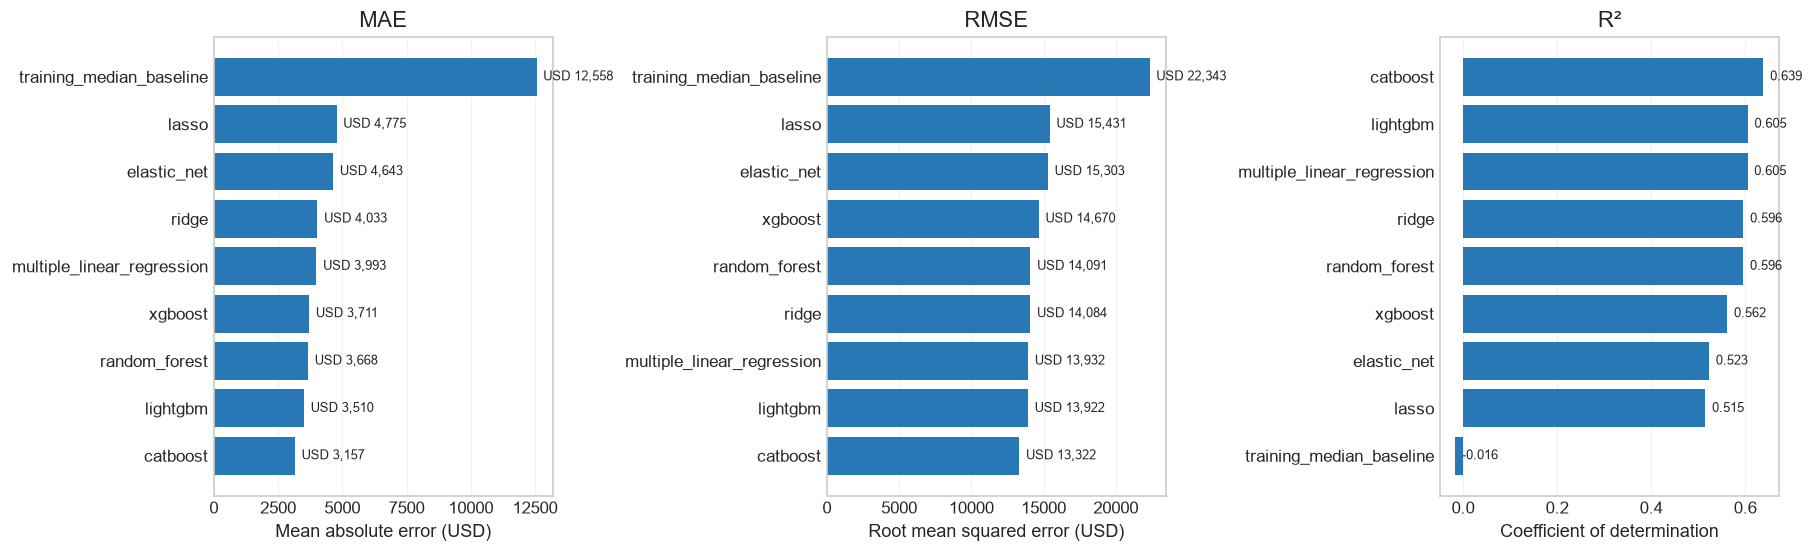

In [47]:
if RUN_AVAILABLE:
    plot_metrics = metrics.set_index("model")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
    panels = [
        ("mae", "MAE", "Mean absolute error (USD)", "USD {:,.0f}"),
        ("rmse", "RMSE", "Root mean squared error (USD)", "USD {:,.0f}"),
        ("r2", "R²", "Coefficient of determination", "{:.3f}"),
    ]
    for axis, (column, title, label, fmt) in zip(axes, panels):
        values = plot_metrics[column].sort_values()
        bars = axis.barh(values.index, values.values, color="#2878B5")
        axis.set_title(title)
        axis.set_xlabel(label)
        axis.grid(axis="x", alpha=0.25)
        axis.grid(axis="y", visible=False)
        for bar, value in zip(bars, values.values):
            axis.annotate(fmt.format(value), (bar.get_width(), bar.get_y()+bar.get_height()/2),
                          xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
    plt.show()

### Saved models and explanation artifacts

This inventory reports files actually present in the selected run. Boosted-tree SHAP files may be absent if they were skipped or unavailable; sklearn models are interpreted in the next section from their fitted estimator.

In [48]:
if RUN_AVAILABLE:
    inventory = []
    for model_name, details in metadata.get("models", {}).items():
        model_file = model_run_dirs[model_name] / model_name / details.get("model_file", "")
        shap_files = details.get("shap_files") or {}
        inventory.append({
            "model": model_name,
            "saved model": str(model_file.relative_to(model_run_dirs[model_name])) if model_file.is_file() else "missing",
            "global SHAP": shap_files.get("global_importance", "not saved"),
            "row SHAP": shap_files.get("row_values", "not saved"),
            "best iteration": details.get("best_iteration"),
            "selected parameters": json.dumps(details.get("selected_parameters") or {}, default=str),
        })
    display(pd.DataFrame(inventory))

,model,saved model,global SHAP,row SHAP,best iteration,selected parameters
0,catboost,catboost\model.cbm,not saved,not saved,800.0,"{""depth"": 8, ""learning_rate"": 0.05, ""l2_leaf_r..."
1,lightgbm,lightgbm\model.joblib,not saved,not saved,799.0,"{""num_leaves"": 63, ""learning_rate"": 0.03, ""min..."
2,xgboost,xgboost\model.json,not saved,not saved,800.0,"{""max_depth"": 4, ""learning_rate"": 0.05, ""min_c..."
3,random_forest,random_forest\model.joblib,not saved,not saved,NaN,"{""model__max_features"": 0.3, ""model__min_sampl..."
4,multiple_linear_regression,multiple_linear_regression\model.joblib,not saved,not saved,NaN,{}
5,lasso,lasso\model.joblib,not saved,not saved,NaN,"{""model__alpha"": 0.001}"
6,ridge,ridge\model.joblib,not saved,not saved,NaN,"{""model__alpha"": 10.0}"
7,elastic_net,elastic_net\model.joblib,not saved,not saved,NaN,"{""model__alpha"": 0.001, ""model__l1_ratio"": 0.5}"


## Random Forest and regression interpretation

Random Forest impurity importance summarizes how often and how strongly encoded inputs reduce split error; it can favor continuous or high-cardinality predictors and is not causal. Regression coefficients show fitted direction and size for each transformed feature. Numeric inputs were standardized, so their coefficient is the estimated USD change per one training standard deviation; one-hot coefficients represent encoded category-level contrasts within the fitted model. Correlated predictors and the full one-hot encoding make individual coefficients less stable, especially for ordinary least squares. These views are model diagnostics, not causal effects.

This section reads saved sklearn pipelines. It reports encoded terms so category-level effects remain visible; the source feature is included for grouping and review.

elastic_net: largest encoded terms by absolute value


,model,interpretation,source feature,encoded term,value
0,elastic_net,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Porsche,0.450399
1,elastic_net,Coefficient (USD per encoded unit),mileage,numeric__mileage,-0.268497
2,elastic_net,Coefficient (USD per encoded unit),horsepower,numeric__horsepower,0.250308
3,elastic_net,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Wrangler Unlimited,0.245599
4,elastic_net,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Mercedes-Benz,0.195597
5,elastic_net,Coefficient (USD per encoded unit),engine_type,categorical__engine_type_value:V8 Diesel,0.166818
6,elastic_net,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Lexus,0.150971
7,elastic_net,Coefficient (USD per encoded unit),fuel_type,categorical__fuel_type_value:Diesel,0.142658
8,elastic_net,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Dodge,-0.130795
9,elastic_net,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Ford,-0.122235


lasso: largest encoded terms by absolute value


,model,interpretation,source feature,encoded term,value
0,lasso,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Porsche,0.400087
1,lasso,Coefficient (USD per encoded unit),mileage,numeric__mileage,-0.269215
2,lasso,Coefficient (USD per encoded unit),horsepower,numeric__horsepower,0.256418
3,lasso,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Mercedes-Benz,0.184359
4,lasso,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Wrangler Unlimited,0.180591
5,lasso,Coefficient (USD per encoded unit),fuel_type,categorical__fuel_type_value:Diesel,0.156533
6,lasso,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Lexus,0.123002
7,lasso,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Dodge,-0.115692
8,lasso,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Ford,-0.098687
9,lasso,Coefficient (USD per encoded unit),engine_type,categorical__engine_type_value:V6 Flex Fuel Ve...,-0.096668


multiple_linear_regression: largest encoded terms by absolute value


,model,interpretation,source feature,encoded term,value
0,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Giulia,-1.843815
1,multiple_linear_regression,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Alfa Romeo,1.725460
2,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Stelvio,-1.722488
3,multiple_linear_regression,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Ferrari,1.198592
4,multiple_linear_regression,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Bentley,0.913561
5,multiple_linear_regression,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Porsche,0.788349
6,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:FJ Cruiser,0.762000
7,multiple_linear_regression,Coefficient (USD per encoded unit),engine_type,categorical__engine_type_value:V12,0.740473
8,multiple_linear_regression,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Corvette,0.700345
9,multiple_linear_regression,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Suzuki,-0.685720


random_forest: largest encoded terms by absolute value


,model,interpretation,source feature,encoded term,value
0,random_forest,Impurity importance,year,numeric__year,0.189222
1,random_forest,Impurity importance,horsepower,numeric__horsepower,0.145297
2,random_forest,Impurity importance,mileage,numeric__mileage,0.128518
3,random_forest,Impurity importance,log1p_mileage,numeric__log1p_mileage,0.120340
4,random_forest,Impurity importance,width,numeric__width,0.057769
5,random_forest,Impurity importance,wheel_system,categorical__wheel_system_value:FWD,0.042700
6,random_forest,Impurity importance,owner_count__missing,numeric__owner_count__missing,0.038777
7,random_forest,Impurity importance,wheelbase,numeric__wheelbase,0.030920
8,random_forest,Impurity importance,engine_displacement,numeric__engine_displacement,0.028121
9,random_forest,Impurity importance,is_new,categorical__is_new_value:False,0.018589


ridge: largest encoded terms by absolute value


,model,interpretation,source feature,encoded term,value
0,ridge,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Ferrari,0.888340
1,ridge,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Porsche,0.613666
2,ridge,Coefficient (USD per encoded unit),engine_type,categorical__engine_type_value:V12,0.584156
3,ridge,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Bentley,0.531476
4,ridge,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Corvette,0.488352
5,ridge,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Saturn,-0.479265
6,ridge,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Suzuki,-0.412059
7,ridge,Coefficient (USD per encoded unit),make_name,categorical__make_name_value:Mercury,-0.411181
8,ridge,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:FJ Cruiser,0.410711
9,ridge,Coefficient (USD per encoded unit),model_name,categorical__model_name_value:Wrangler Unlimited,0.382070


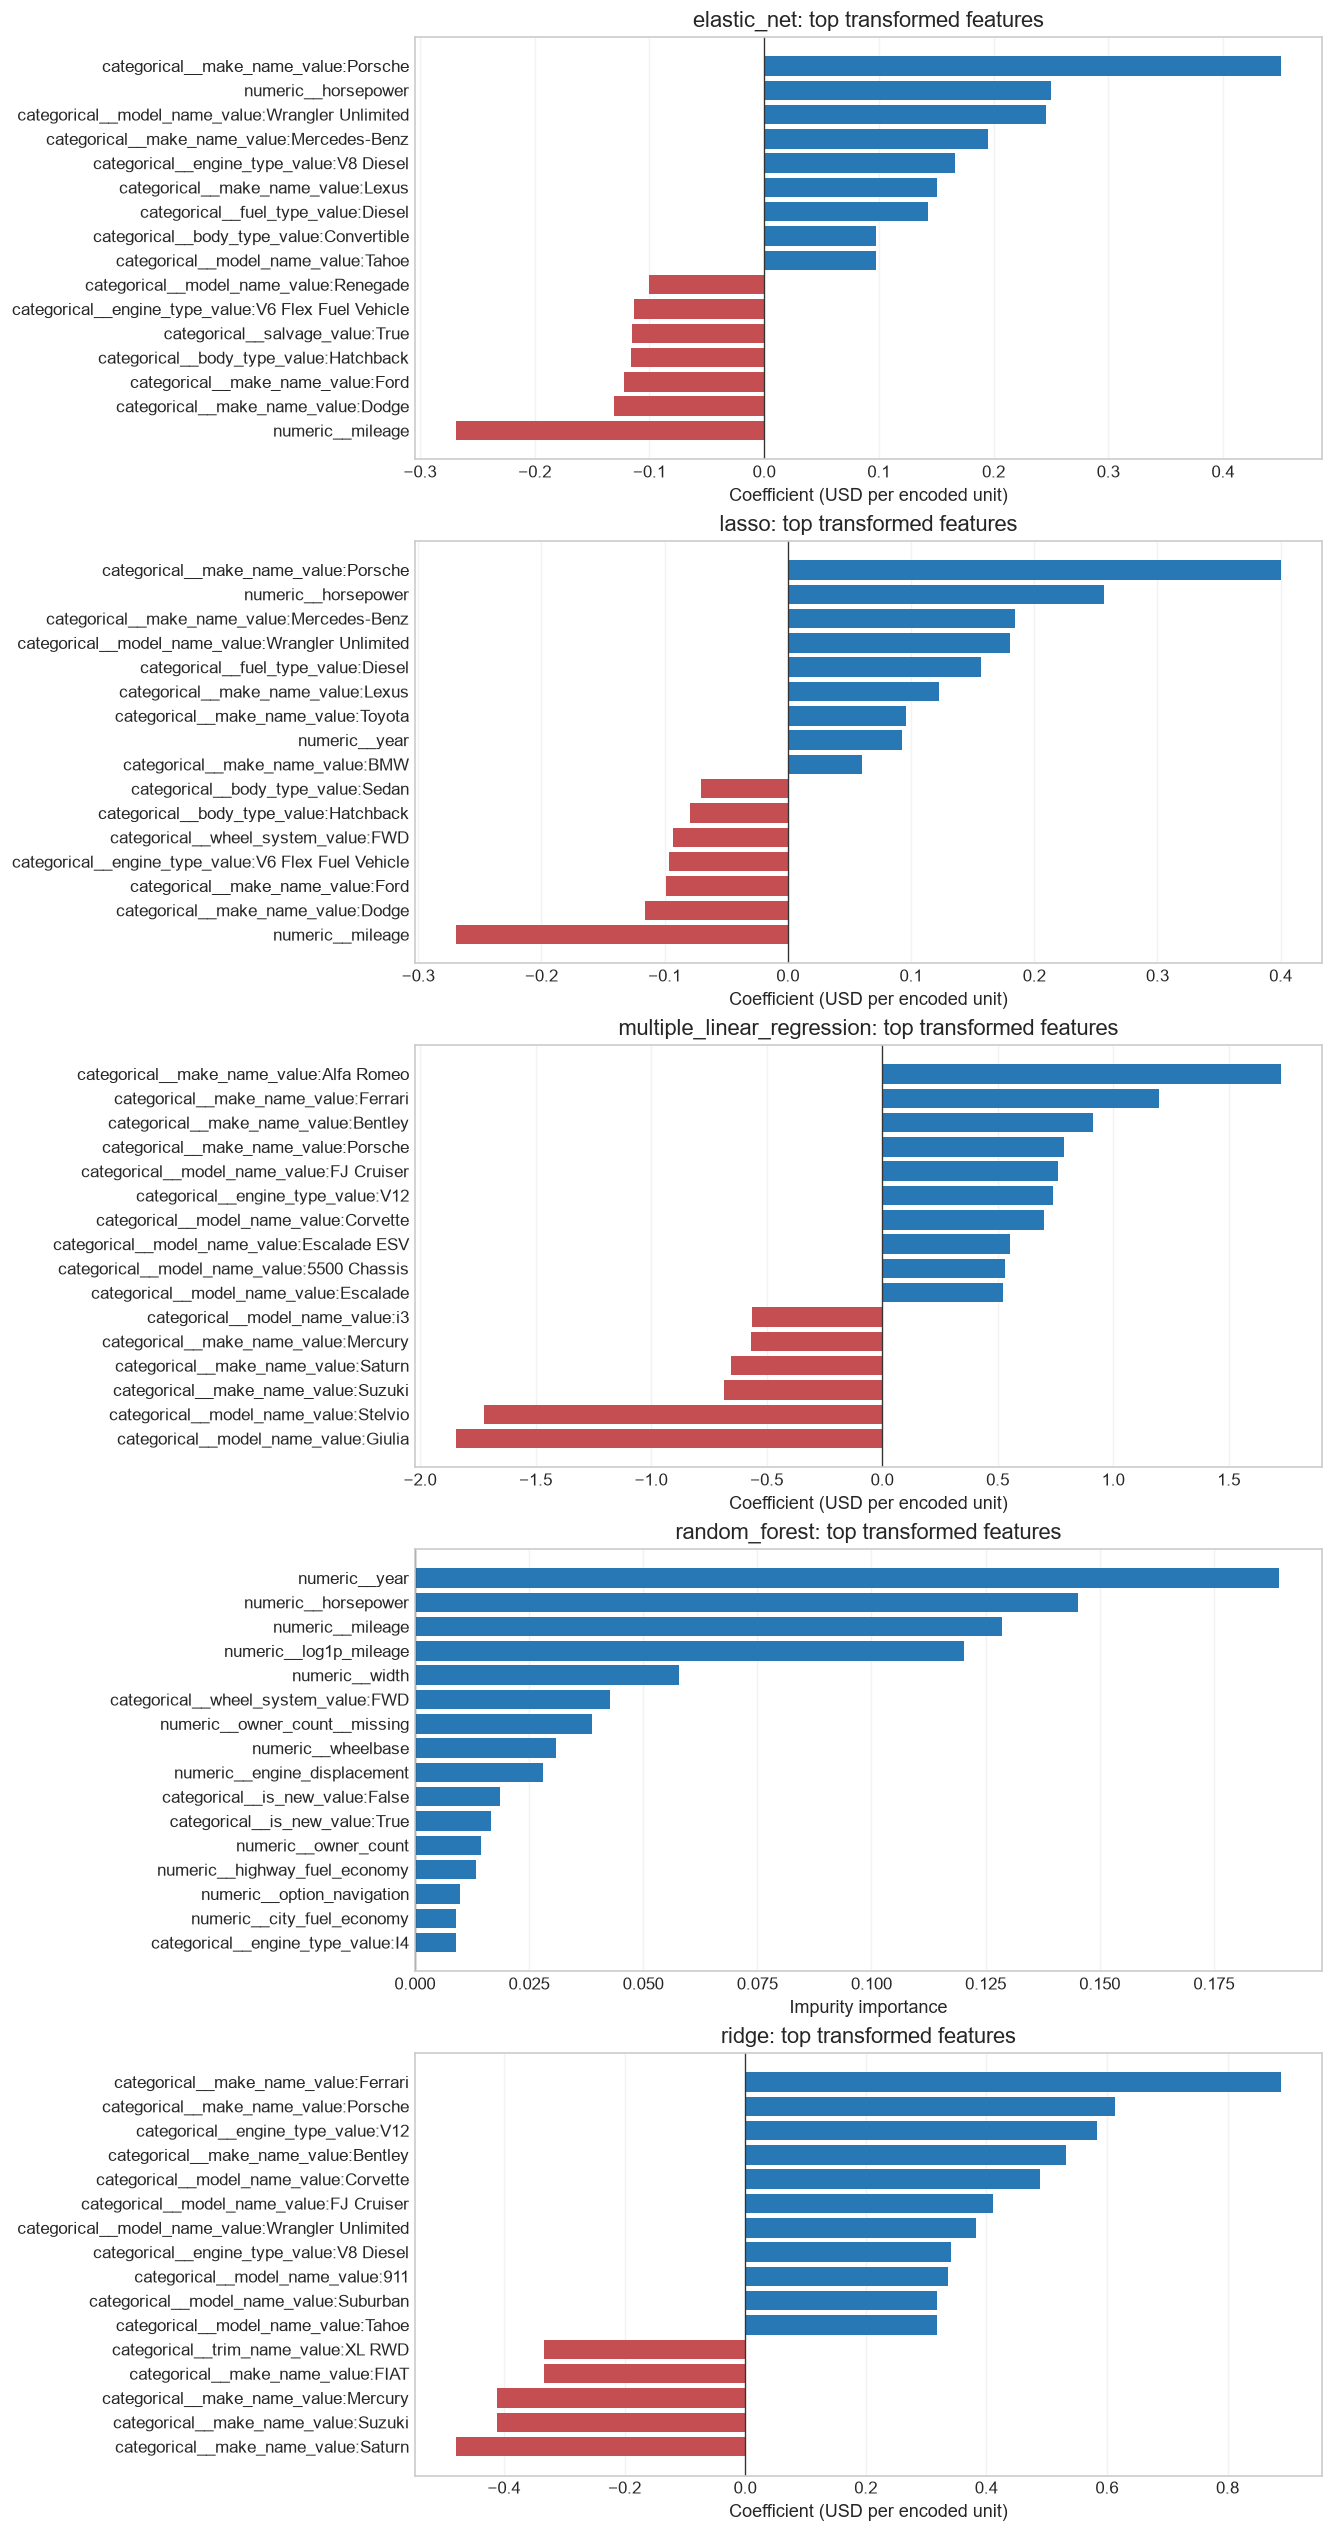

In [49]:
if RUN_AVAILABLE:
    classical_names = {
        "random_forest", "multiple_linear_regression", "lasso", "ridge", "elastic_net"
    }
    interpretation_rows = []
    interpretation_models = []
    categorical_features = metadata.get("categorical_features", [])

    def source_feature_for_term(term):
        if term.startswith("numeric__"):
            return term.removeprefix("numeric__")
        encoded = term.removeprefix("categorical__")
        matches = [name for name in categorical_features
                   if encoded == name or encoded.startswith(name + "_")]
        return max(matches, key=len) if matches else encoded

    for model_name in sorted(classical_names & set(metadata.get("models", {}))):
        details = metadata["models"][model_name]
        model_path = model_run_dirs[model_name] / model_name / details.get("model_file", "")
        if not model_path.is_file() or model_path.suffix != ".joblib":
            continue
        import joblib
        pipeline = joblib.load(model_path)
        model = pipeline.named_steps["model"]
        terms = pipeline.named_steps["preprocess"].get_feature_names_out()
        if model_name == "random_forest":
            values = model.feature_importances_
            kind = "Impurity importance"
        else:
            values = model.coef_
            kind = "Coefficient (USD per encoded unit)"
        if len(terms) != len(values):
            raise ValueError(f"Transformed feature count does not match {model_name} parameters")
        frame = pd.DataFrame({
            "model": model_name,
            "interpretation": kind,
            "source feature": [source_feature_for_term(term) for term in terms],
            "encoded term": terms,
            "value": values,
        })
        frame["absolute value"] = frame["value"].abs()
        interpretation_rows.append(frame)
        interpretation_models.append((model_name, frame))

    if not interpretation_rows:
        display(Markdown(
            "No Random Forest or regression model artifacts are present in this run. "
            "Run the updated Price_ML_Models.py pilot with those model names, then select "
            "that completed run here."
        ))
    else:
        interpretations = pd.concat(interpretation_rows, ignore_index=True)
        for model_name, frame in interpretation_models:
            print(f"{model_name}: largest encoded terms by absolute value")
            display(frame.nlargest(20, "absolute value").drop(columns="absolute value")
                    .reset_index(drop=True))

        fig, axes = plt.subplots(len(interpretation_models), 1,
                                 figsize=(11, 4.2 * len(interpretation_models)),
                                 squeeze=False, constrained_layout=True)
        for axis, (model_name, frame) in zip(axes[:, 0], interpretation_models):
            top = frame.nlargest(16, "absolute value").sort_values("value")
            colors = ["#C44E52" if value < 0 else "#2878B5" for value in top["value"]]
            axis.barh(top["encoded term"], top["value"], color=colors)
            axis.axvline(0, color="#333333", linewidth=0.8)
            axis.set_title(f"{model_name}: top transformed features")
            axis.set_xlabel("Impurity importance" if model_name == "random_forest"
                            else "Coefficient (USD per encoded unit)")
            axis.set_ylabel("")
            axis.grid(axis="x", alpha=0.25)
            axis.grid(axis="y", visible=False)
        plt.show()

## SHAP: global feature importance

Mean absolute SHAP values summarize contribution size on the model output scale, natural-log listed price for the bounded held-out explanation rows. They describe model attribution, not causation.

In [50]:
if RUN_AVAILABLE:
    global_paths = sorted({path for run_path in selected_runs
                           for path in run_path.glob("*/*_shap_global.csv")})
    frames = []
    for path in global_paths:
        values = pd.read_csv(path)
        if {"feature", "mean_absolute_shap"} <= set(values.columns):
            values["model"] = path.name.removesuffix("_shap_global.csv")
            frames.append(values)
    if not frames:
        display(Markdown("No global SHAP files were found for this run."))
    else:
        shap_global = pd.concat(frames, ignore_index=True)
        shap_models = shap_global["model"].unique().tolist()
        fig, axes = plt.subplots(1, len(shap_models), figsize=(6*len(shap_models), 7),
                                 squeeze=False, constrained_layout=True)
        for axis, model_name in zip(axes[0], shap_models):
            top = (shap_global[shap_global["model"] == model_name]
                   .nlargest(20, "mean_absolute_shap").sort_values("mean_absolute_shap"))
            axis.barh(top["feature"], top["mean_absolute_shap"], color="#2878B5")
            axis.set_title(f"{model_name}: top features")
            axis.set_xlabel("Mean absolute SHAP value (ln USD)")
            axis.set_ylabel("")
        plt.show()
        display(shap_global.sort_values(
            ["model", "mean_absolute_shap"], ascending=[True, False]
        ).groupby("model").head(10).reset_index(drop=True))

No global SHAP files were found for this run.

### Inspect one row-level explanation

The chart shows the largest signed contributions for one explained test row. SHAP contributions and the base value are on the natural-log listed-price scale. Original feature values are not included in the runner’s SHAP artifact. SHAP contributions explain the model output relative to its baseline; they are not causal effects.

In [51]:
if RUN_AVAILABLE:
    row_shap_paths = sorted({path for run_path in selected_runs
                              for path in run_path.glob("*/*_shap_values.parquet")})
    if not row_shap_paths:
        display(Markdown("No row-level SHAP files were found for this run."))
    else:
        row_path = row_shap_paths[0]
        row_shap = pd.read_parquet(row_path)
        required = {"test_row", "actual_price", "actual_log_price", "predicted_log_price", "base_value_log_price"}
        if required - set(row_shap.columns):
            raise ValueError(f"SHAP file missing columns: {sorted(required - set(row_shap.columns))}")
        row_index = min(max(int(SHAP_ROW), 0), len(row_shap) - 1)
        explanation = row_shap.iloc[row_index]
        features = [c for c in metadata.get("feature_columns", []) if c in row_shap.columns]
        contributions = explanation[features].astype(float)
        top = contributions.loc[
            contributions.abs().nlargest(min(15, len(contributions))).index
        ].sort_values()
        colors = ["#C44E52" if value < 0 else "#2878B5" for value in top.values]
        print(f"Model: {row_path.parent.name}; sample row: {row_index}; "
              f"actual=USD {explanation['actual_price']:,.0f}; "
              f"prediction=USD {np.exp(explanation['predicted_log_price']):,.0f}")
        reconstructed_log = float(explanation["base_value_log_price"] + contributions.sum())
        print(f"Base plus all SHAP contributions: ln(USD) {reconstructed_log:.4f}; reconstructed price USD {np.exp(reconstructed_log):,.0f}")
        fig, axis = plt.subplots(figsize=(9, 6), constrained_layout=True)
        axis.barh(top.index, top.values, color=colors)
        axis.axvline(0, color="#333333", linewidth=0.8)
        axis.set_title("Largest signed SHAP contributions for one test row")
        axis.set_xlabel("Contribution to ln(listed price in USD)")
        axis.set_ylabel("")
        plt.show()
        display(row_shap.iloc[[row_index]])

No row-level SHAP files were found for this run.

### Held-out prediction diagnostics

Residual plots use every held-out prediction. The scatter is sampled for readability; the residual histogram uses the full test set.

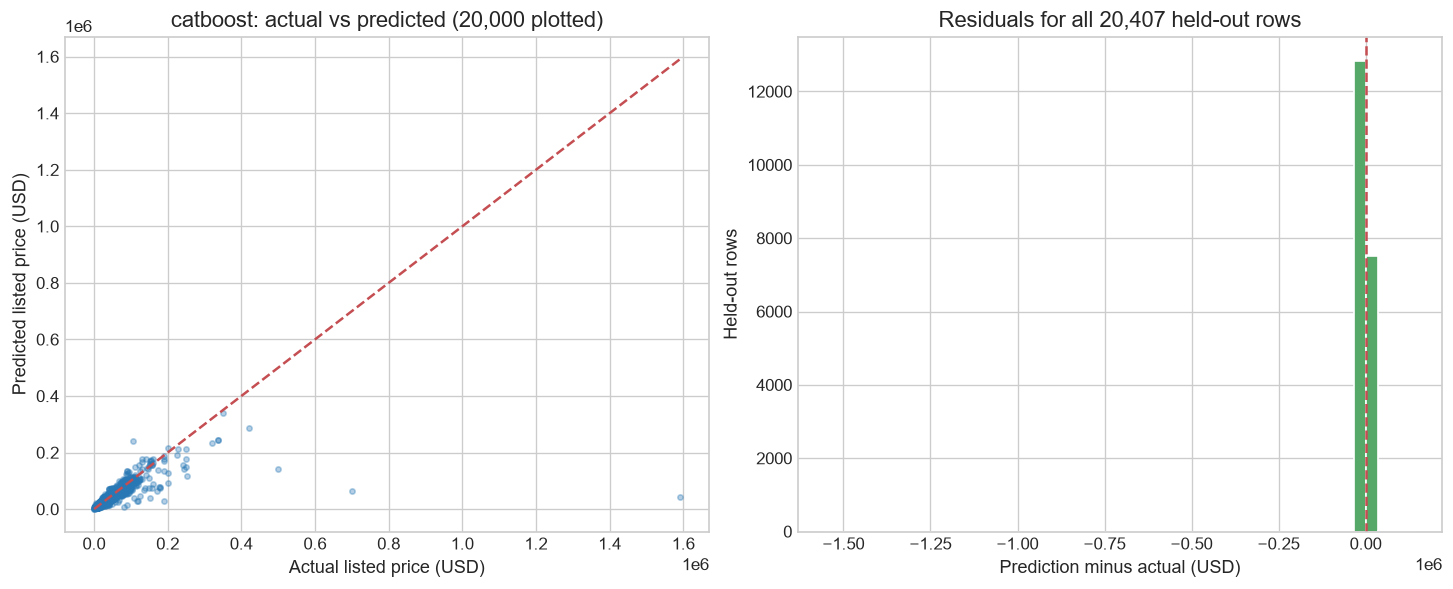

In [52]:
if RUN_AVAILABLE:
    ranked = (metrics[(metrics.model != "training_median_baseline") & metrics.validation_mae.notna()]
              if "validation_mae" in metrics else pd.DataFrame())
    diagnostic_model = ranked.sort_values("validation_mae").iloc[0]["model"] if not ranked.empty else None
    if diagnostic_model is None and not metrics.empty:
        diagnostic_model = metrics.iloc[0]["model"]
    prediction_path = (model_run_dirs[diagnostic_model] / f"{diagnostic_model}_test_predictions.parquet"
                       if diagnostic_model is not None else None)
    if prediction_path is None or not prediction_path.is_file():
        display(Markdown("No full held-out prediction file is available for residual diagnostics."))
    else:
        diagnostics = pd.read_parquet(prediction_path)
        plot_rows = diagnostics.sample(min(20000, len(diagnostics)), random_state=42) if len(diagnostics) > 20000 else diagnostics
        residual = diagnostics["prediction"] - diagnostics["actual_price"]
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
        axes[0].scatter(plot_rows["actual_price"], plot_rows["prediction"],
                        s=10, alpha=0.35, color="#2878B5")
        lower = min(diagnostics["actual_price"].min(), diagnostics["prediction"].min())
        upper = max(diagnostics["actual_price"].max(), diagnostics["prediction"].max())
        axes[0].plot([lower, upper], [lower, upper], "--", color="#C44E52")
        axes[0].set_title(f"{diagnostic_model}: actual vs predicted ({len(plot_rows):,} plotted)")
        axes[0].set_xlabel("Actual listed price (USD)")
        axes[0].set_ylabel("Predicted listed price (USD)")
        axes[1].hist(residual, bins=50, color="#55A868", edgecolor="white")
        axes[1].axvline(0, linestyle="--", color="#C44E52")
        axes[1].set_title(f"Residuals for all {len(diagnostics):,} held-out rows")
        axes[1].set_xlabel("Prediction minus actual (USD)")
        axes[1].set_ylabel("Held-out rows")
        plt.show()


## Takeaways

The summary is generated from the selected run’s full metrics table. SHAP and residual plots use only the bounded explained sample.

In [53]:
if RUN_AVAILABLE:
    ranked = (metrics[(metrics.model != "training_median_baseline") & metrics.validation_mae.notna()]
              if "validation_mae" in metrics else pd.DataFrame())
    if ranked.empty:
        display(Markdown("No validation selection is available for this legacy run. Test scores are descriptive only."))
    else:
        chosen = ranked.sort_values("validation_mae").iloc[0]
        display(Markdown(
            f"**Selected ML model by validation MAE:** {chosen['model']} (USD {chosen['validation_mae']:,.0f}). "
            f"Its held-out test MAE is USD {chosen['mae']:,.0f} across {int(chosen['test_rows']):,} listings. "
            "These are advertised prices, not sale prices. Inspect new/used, incomplete-cohort, and extreme-value segments below."
        ))
    segment_frames = [pd.read_csv(p / "segment_metrics.csv") for p in selected_runs if (p / "segment_metrics.csv").is_file()]
    if segment_frames:
        display(pd.concat(segment_frames, ignore_index=True).drop_duplicates(["model", "dimension", "segment"]))
    else:
        display(Markdown("This legacy run has no saved segment metrics."))
    year_make_frames = [pd.read_csv(p / "year_make_metrics.csv") for p in selected_runs
                        if (p / "year_make_metrics.csv").is_file()]
    if year_make_frames:
        year_make = pd.concat(year_make_frames, ignore_index=True)
        selected_model = metadata.get("selected_by_validation_mae")
        if selected_model in set(year_make["model"]):
            year_make = year_make[year_make["model"] == selected_model]
        display(Markdown("**Selected model errors by decoded model year and make.** Low-support groups are exploratory. The full set of year/make rows is saved in `year_make_metrics.csv`."))
        formats = {"median_actual_price": "USD {:,.0f}", "mae_usd": "USD {:,.0f}",
            "rmse_usd": "USD {:,.0f}", "mean_signed_error_usd": "USD {:,.0f}",
            "p90_absolute_error_usd": "USD {:,.0f}", "wape_pct": "{:.1f}%",
            "mae_pct_of_median_price": "{:.1f}%", "rows": "{:,.0f}",
            "family_blocks": "{:,.0f}", "r2": "{:.4f}"}
        display(Markdown("**By model year**"))
        display(year_make[year_make.metric_level == "year"].sort_values("ModelYear").style.format(formats, na_rep="—"))
        display(Markdown("**By make**"))
        display(year_make[year_make.metric_level == "make"].sort_values("Make", na_position="last").style.format(formats, na_rep="—"))
        year_make_pairs = year_make[(year_make.metric_level == "year_make") & (year_make.support_status == "supported")]
        display(Markdown("**Supported year/make groups with the most test listings (up to 100)**"))
        display(year_make_pairs.nlargest(100, "rows").sort_values(["ModelYear", "Make"], na_position="last").style.format(formats, na_rep="—"))
    else:
        display(Markdown("No year/make metrics are available for this legacy run."))
else:
    display(Markdown("No completed run is selected."))


**Selected ML model by validation MAE:** catboost (USD 2,852). Its held-out test MAE is USD 3,157 across 20,407 listings. These are advertised prices, not sale prices. Inspect new/used, incomplete-cohort, and extreme-value segments below.

,model,dimension,segment,rows,mae,rmse,p95_absolute_error
0,training_median_baseline,is_new,False,10281,11984.361443,24177.127463,2.229200e+04
1,training_median_baseline,is_new,True,10126,13139.605570,20311.910400,4.072925e+04
2,training_median_baseline,cohort_complete,False,3113,15995.355284,41301.122439,4.081120e+04
3,training_median_baseline,cohort_complete,True,17294,11938.783682,16793.373101,3.294150e+04
4,training_median_baseline,split_identity_source,listing_identity_fallback,33,75694.454545,276248.644134,1.246580e+05
...,...,...,...,...,...,...,...
121,elastic_net,price_band,50k-100k,1985,10680.511566,13872.491466,2.598200e+04
122,elastic_net,price_band,>100k,102,101850.572934,196862.287802,2.310085e+05
123,elastic_net,mileage_review_flag,False,20407,4643.497050,15303.389047,1.377092e+04
124,elastic_net,price_review_flag,False,20404,4535.909523,9846.844115,1.374849e+04


**Selected model errors by decoded model year and make.** Low-support groups are exploratory. The full set of year/make rows is saved in `year_make_metrics.csv`.

**By model year**

,model,metric_level,ModelYear,Make,rows,family_blocks,median_actual_price,mae_usd,rmse_usd,mean_signed_error_usd,p90_absolute_error_usd,wape_pct,mae_pct_of_median_price,support_status
587,catboost,year,1983.000000,—,1,1,"USD 18,950","USD 11,913","USD 11,913","USD -11,913","USD 11,913",62.9%,62.9%,low_support
588,catboost,year,1985.000000,—,1,1,"USD 12,969","USD 3,729","USD 3,729","USD -3,729","USD 3,729",28.8%,28.8%,low_support
589,catboost,year,1987.000000,—,4,4,"USD 28,750","USD 16,480","USD 20,526","USD -11,787","USD 29,536",53.0%,57.3%,low_support
590,catboost,year,1988.000000,—,1,1,"USD 39,959","USD 21,707","USD 21,707","USD -21,707","USD 21,707",54.3%,54.3%,low_support
591,catboost,year,1989.000000,—,3,2,"USD 175,900","USD 62,277","USD 71,711","USD -52,773","USD 94,032",48.9%,35.4%,low_support
592,catboost,year,1992.000000,—,7,6,"USD 9,500","USD 37,003","USD 65,965","USD -34,226","USD 119,401",53.4%,389.5%,low_support
593,catboost,year,1993.000000,—,4,4,"USD 6,219","USD 1,832","USD 2,276",USD 716,"USD 3,338",31.5%,29.5%,low_support
594,catboost,year,1994.000000,—,2,2,"USD 5,000",USD 701,USD 991,USD 701,"USD 1,261",14.0%,14.0%,low_support
595,catboost,year,1995.000000,—,3,2,"USD 17,999","USD 13,119","USD 14,601","USD -13,119","USD 19,642",59.6%,72.9%,low_support
596,catboost,year,1996.000000,—,8,6,"USD 6,748","USD 16,257","USD 39,848","USD -13,511","USD 36,518",63.6%,240.9%,low_support


**By make**

,model,metric_level,ModelYear,Make,rows,family_blocks,median_actual_price,mae_usd,rmse_usd,mean_signed_error_usd,p90_absolute_error_usd,wape_pct,mae_pct_of_median_price,support_status
623,catboost,make,—,ACURA,146,18,"USD 26,447","USD 2,209","USD 3,589",USD 463,"USD 4,206",7.3%,8.4%,supported
624,catboost,make,—,ALFA ROMEO,56,2,"USD 43,870","USD 4,852","USD 5,880","USD -4,018","USD 9,601",11.3%,11.1%,low_support
625,catboost,make,—,ASTON MARTIN,7,4,"USD 243,366","USD 78,180","USD 82,626","USD -57,360","USD 100,281",32.6%,32.1%,low_support
626,catboost,make,—,AUDI,310,35,"USD 34,768","USD 4,368","USD 6,382","USD -2,449","USD 10,900",11.1%,12.6%,supported
627,catboost,make,—,BENTLEY,4,3,"USD 110,945","USD 15,151","USD 19,621","USD -5,200","USD 29,421",13.6%,13.7%,low_support
628,catboost,make,—,BMW,297,56,"USD 26,994","USD 6,126","USD 11,779","USD -1,258","USD 19,135",16.1%,22.7%,supported
629,catboost,make,—,BUICK,240,14,"USD 17,038","USD 1,280","USD 1,748",USD 387,"USD 2,843",7.5%,7.5%,supported
630,catboost,make,—,CADILLAC,263,19,"USD 47,864","USD 3,736","USD 4,989","USD -2,419","USD 8,328",9.1%,7.8%,supported
631,catboost,make,—,CHEVROLET,"1,767",64,"USD 19,998","USD 2,952","USD 4,786","USD -1,302","USD 8,570",10.6%,14.8%,supported
632,catboost,make,—,CHRYSLER,527,16,"USD 31,580","USD 3,198","USD 4,626","USD -2,265","USD 8,063",10.9%,10.1%,supported


**Supported year/make groups with the most test listings (up to 100)**

,model,metric_level,ModelYear,Make,rows,family_blocks,median_actual_price,mae_usd,rmse_usd,mean_signed_error_usd,p90_absolute_error_usd,wape_pct,mae_pct_of_median_price,support_status
981,catboost,year_make,2014.000000,FORD,172,5,"USD 10,542",USD 913,"USD 1,275",USD 68,"USD 1,935",8.3%,8.7%,supported
999,catboost,year_make,2015.000000,CHEVROLET,115,5,"USD 13,995","USD 1,218","USD 1,841",USD 340,"USD 2,879",7.4%,8.7%,supported
1038,catboost,year_make,2016.000000,NISSAN,184,5,"USD 14,268","USD 1,006","USD 1,285",USD 159,"USD 2,062",7.0%,7.0%,supported
1045,catboost,year_make,2017.000000,AUDI,117,6,"USD 31,199","USD 2,801","USD 3,761","USD -2,144","USD 6,011",8.8%,9.0%,supported
1054,catboost,year_make,2017.000000,FORD,117,7,"USD 32,995","USD 3,906","USD 5,257","USD -1,417","USD 8,346",10.8%,11.8%,supported
1138,catboost,year_make,2020.000000,FORD,"2,778",5,"USD 30,552","USD 3,832","USD 5,016","USD -2,490","USD 8,003",11.0%,12.5%,supported


## Compare feature sets

This section compares the listing-only `base` model with the `enriched` model. Enriched adds vPIC, complaint/recall aggregates, and safety summaries. Paired prediction comparisons require compatible run fingerprints and identical held-out VINs/targets. The report includes year, make, and year-by-make MAE changes on those same listings. Group-bootstrap intervals resample held-out year/make/model split blocks. Issue features use the documented provisional cutoff, and results are retrospective because the listing price observation date is unverified.

Train both feature sets with the same sample, estimator, and split strategy, then rerun the notebook from the top. Set `RUN_PATHS` to pin a specific completed run.

**Forecast overview.** Model selection uses validation MAE; test metrics use untouched held-out groups.

,eligible listings,test listings,test split groups,predictors,selected ML model,validation MAE (USD),ML test MAE (USD),ML test RMSE (USD),median-baseline test MAE (USD)
feature set,,,,,,,,,
base,"100,000","20,407",973,39,catboost,"USD 2,852",3156.544052,13322.498997,12557.596217
enriched,"100,000","20,407",973,113,catboost,"USD 2,767",3151.267333,13377.992632,12557.596217


**Matched test-set comparisons.** Negative expanded-minus-reference values mean lower row-weighted MAE. Intervals resample split groups and summarize the group-macro MAE change; they are conditional on the fitted runs.

,comparison,status
0,base vs enriched,incompatible run fingerprints


Source-specific feature-set ablations have been consolidated into `enriched`.

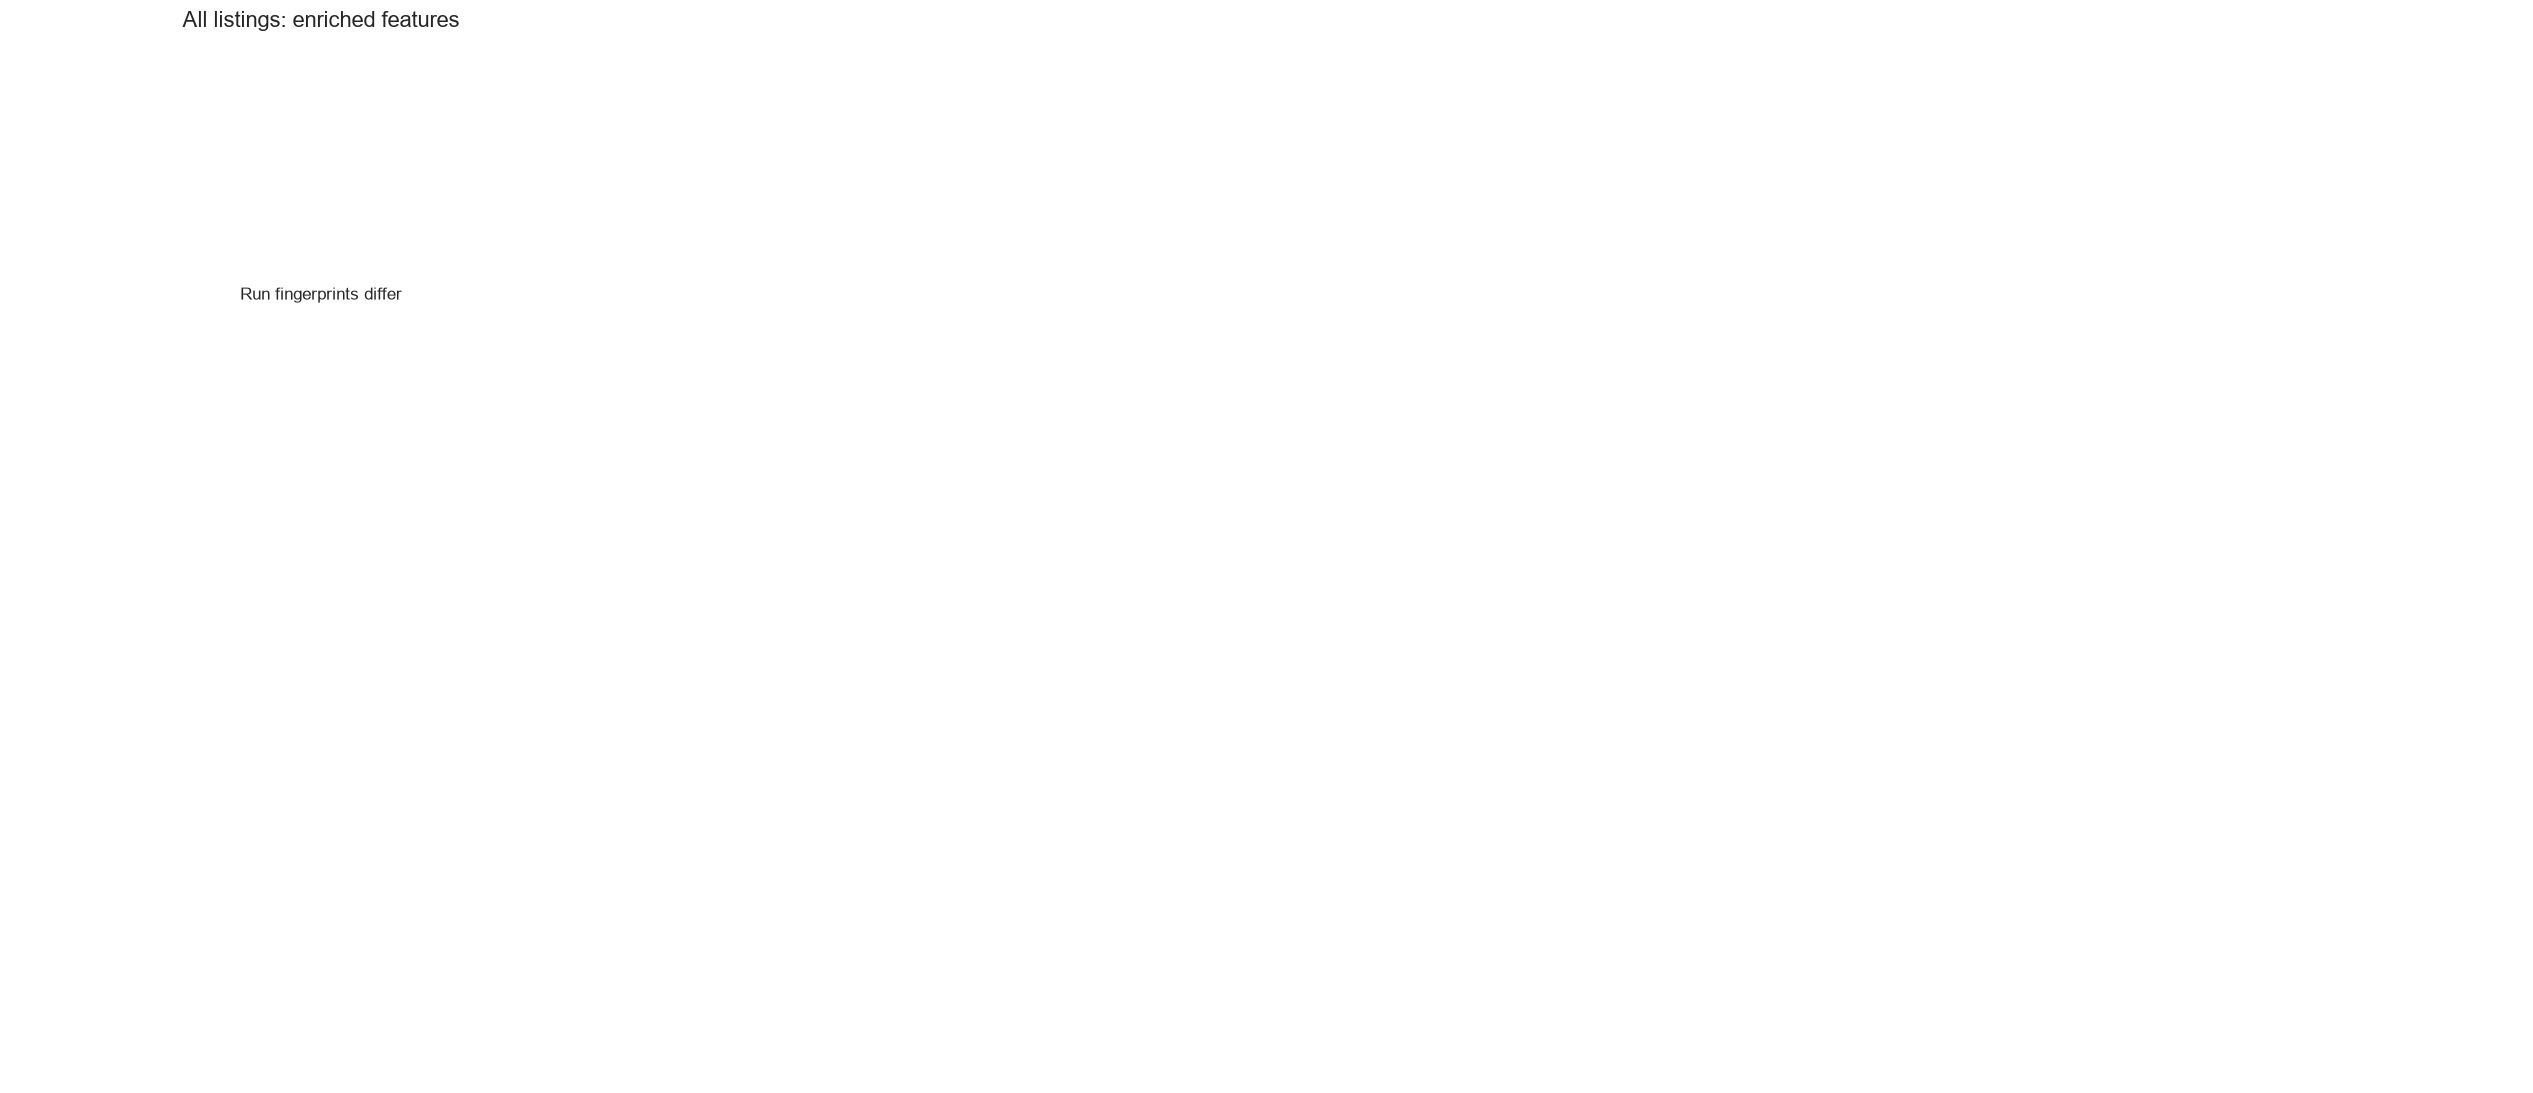

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def completed_runs(model_type):
    folder = MODEL_OUTPUT_DIR / model_type
    runs = []
    if folder.is_dir():
        for path in sorted(folder.iterdir(), key=lambda item: item.name, reverse=True):
            meta_file = path / "run_metadata.json"
            if path.is_dir() and (path / "metrics.csv").is_file() and meta_file.is_file():
                meta = json.loads(meta_file.read_text(encoding="utf-8"))
                if meta.get("status", "completed") == "completed":
                    runs.append(path)
    override = RUN_PATHS.get(model_type)
    if override:
        path = Path(override)
        if not path.is_absolute(): path = PROJECT_ROOT / path
        if path not in runs:
            raise ValueError(f"RUN_PATHS[{model_type!r}] must identify a completed MODEL_OUTPUT run")
        return [path] + [run for run in runs if run != path]
    return runs

COMPARISON_PAIRS = [
    ("base", "enriched", "All listings: enriched features"),
]

# Resolve the newest completed run per requested feature set, unless pinned above.
comparison_run, comparison_meta, comparison_metrics = {}, {}, {}
for kind in COMPARISON_MODEL_TYPES:
    available = completed_runs(kind)
    if available:
        comparison_run[kind] = available[0]
        comparison_meta[kind] = json.loads((available[0] / "run_metadata.json").read_text(encoding="utf-8"))
        comparison_metrics[kind] = pd.read_csv(available[0] / "metrics.csv").set_index("model")

forecast_rows = []
paired_segment_rows = []
for kind, run_path in comparison_run.items():
    meta, scores = comparison_meta[kind], comparison_metrics[kind]
    selected = meta.get("selected_by_validation_mae")
    eligible = scores.drop(index=["training_median_baseline"], errors="ignore").reset_index()
    eligible = eligible.dropna(subset=["validation_mae"])
    if selected not in eligible.model.to_list() and not eligible.empty:
        selected = eligible.sort_values("validation_mae").iloc[0]["model"]
    winner = scores.loc[selected] if selected in scores.index else None
    baseline_score = scores.loc["training_median_baseline"] if "training_median_baseline" in scores.index else None
    forecast_rows.append({
        "feature set": kind, "eligible listings": meta.get("rows_after_filters"),
        "test listings": meta.get("test_rows"), "test split groups": meta.get("test_split_groups"),
        "predictors": len(meta.get("raw_feature_columns", [])), "selected ML model": selected,
        "validation MAE (USD)": None if winner is None else winner["validation_mae"],
        "ML test MAE (USD)": None if winner is None else winner["mae"],
        "ML test RMSE (USD)": None if winner is None else winner["rmse"],
        "ML test R²": None if winner is None else winner.get("r2"),
        "ML validation R²": None if winner is None else winner.get("validation_r2"),
        "training weighting": meta.get("price_weighting", "none"),
        "median-baseline test MAE (USD)": None if baseline_score is None else baseline_score["mae"],
    })
if forecast_rows:
    display(Markdown("**Forecast overview.** Model selection uses validation MAE; test metrics use untouched held-out groups."))
    display(pd.DataFrame(forecast_rows).set_index("feature set").style.format({
        "validation MAE (USD)": "USD {:,.0f}", "test MAE (USD)": "USD {:,.0f}",
        "test RMSE (USD)": "USD {:,.0f}", "ML test R²": "{:.4f}", "ML validation R²": "{:.4f}", "eligible listings": "{:,.0f}",
        "test listings": "{:,.0f}", "test split blocks": "{:,.0f}"}, na_rep="—"))
else:
    display(Markdown("No completed runs are available yet. Train matched feature sets, then rerun the notebook."))

fig, axes = plt.subplots(2, 4, figsize=(21, 9), constrained_layout=True)
paired_rows, any_plot = [], False
rng = np.random.default_rng(42)
for ax, (reference, expanded, label) in zip(axes.flat, COMPARISON_PAIRS):
    if reference not in comparison_run or expanded not in comparison_run:
        ax.set_title(label); ax.text(.5, .5, "Both completed runs are needed", ha="center", va="center")
        ax.set_axis_off(); continue
    left, right = comparison_meta[reference], comparison_meta[expanded]
    if not compatible_run_metadata(left, right, allow_feature_set=True):
        paired_rows.append({"comparison": f"{reference} vs {expanded}", "status": "incompatible run fingerprints"})
        ax.set_title(label); ax.text(.5, .5, "Run fingerprints differ", ha="center", va="center")
        ax.set_axis_off(); continue
    common = sorted((set(comparison_metrics[reference].index) & set(comparison_metrics[expanded].index)) - {"training_median_baseline"})
    chart_rows = []
    for model in common:
        lp = pd.read_parquet(comparison_run[reference] / f"{model}_test_predictions.parquet")
        rp = pd.read_parquet(comparison_run[expanded] / f"{model}_test_predictions.parquet")
        columns = ["vin", "actual_price", "prediction", "split_group", "ModelYear", "Make", "family_block"]
        pair = lp[columns].merge(rp[columns], on="vin", suffixes=("_ref", "_expanded"), validate="one_to_one")
        same_rows = (len(pair) == len(lp) == len(rp)
                     and np.allclose(pair.actual_price_ref, pair.actual_price_expanded)
                     and (pair.split_group_ref == pair.split_group_expanded).all()
                     and pair.ModelYear_ref.equals(pair.ModelYear_expanded)
                     and pair.Make_ref.equals(pair.Make_expanded))
        if not same_rows:
            paired_rows.append({"comparison": f"{reference} vs {expanded}", "model": model, "status": "held-out rows/groups differ"})
            continue
        pair["reference_error"] = (pair.prediction_ref-pair.actual_price_ref).abs()
        pair["expanded_error"] = (pair.prediction_expanded-pair.actual_price_expanded).abs()
        group_errors = pair.groupby("split_group_ref")[["reference_error", "expanded_error"]].mean()
        group_delta = (group_errors.expanded_error-group_errors.reference_error).to_numpy()
        bootstrap = np.array([group_delta[rng.integers(0,len(group_delta),len(group_delta))].mean() for _ in range(2000)])
        mae_ref, mae_exp = pair.reference_error.mean(), pair.expanded_error.mean()
        paired_rows.append({"comparison": f"{reference} vs {expanded}", "model": model,
            "test listings": len(pair), "reference MAE (USD)": mae_ref, "expanded MAE (USD)": mae_exp,
            "expanded minus reference MAE (USD)": mae_exp-mae_ref,
            "group-macro MAE change (USD)": group_delta.mean(),
            "paired group bootstrap 95% low": np.quantile(bootstrap,.025),
            "paired group bootstrap 95% high": np.quantile(bootstrap,.975),
            "held-out groups": len(group_delta), "status": "same held-out listings"})
        chart_rows.append((model,mae_ref,mae_exp))
        for level, cols in (("year", ["ModelYear_ref"]), ("make", ["Make_ref"]),
                            ("year_make", ["ModelYear_ref", "Make_ref"])):
            for key, part in pair.groupby(cols, observed=True, dropna=False, sort=True):
                values = key if isinstance(key, tuple) else (key,)
                item = {"comparison": f"{reference} vs {expanded}", "model": model,
                        "metric_level": level, "ModelYear": None, "Make": None}
                item.update(dict(zip(["ModelYear", "Make"],
                    values if level == "year_make" else ((values[0], None) if level == "year" else (None, values[0])))))
                ref_mae = float(part.reference_error.mean())
                exp_mae = float(part.expanded_error.mean())
                family_count = int(part.family_block_ref.nunique(dropna=False))
                item.update({"rows": len(part), "family_blocks": family_count,
                    "reference_mae_usd": ref_mae, "enriched_mae_usd": exp_mae,
                    "enriched_minus_base_mae_usd": exp_mae-ref_mae,
                    "support_status": "supported" if len(part) >= 100 and family_count >= 5 else "low_support"})
                paired_segment_rows.append(item)
    if chart_rows:
        pd.DataFrame(chart_rows,columns=["model","reference","expanded"]).set_index("model").plot(
            kind="barh",ax=ax,color=["#5470C6","#91CC75"],width=.78)
        ax.set_title(label); ax.set_xlabel("Held-out MAE (USD)"); ax.set_ylabel("")
        ax.legend([reference,expanded],frameon=False); ax.grid(axis="x",alpha=.25); any_plot=True
    else:
        ax.set_title(label); ax.text(.5,.5,"No shared model prediction files",ha="center",va="center"); ax.set_axis_off()
for ax in list(axes.flat)[len(COMPARISON_PAIRS):]: ax.set_axis_off()
if any_plot: plt.show()
if paired_rows:
    display(Markdown("**Matched test-set comparisons.** Negative expanded-minus-reference values mean lower row-weighted MAE. Intervals resample split groups and summarize the group-macro MAE change; they are conditional on the fitted runs."))
    display(pd.DataFrame(paired_rows))
if paired_segment_rows:
    paired_segments = pd.DataFrame(paired_segment_rows)
    display(Markdown("**Where enriched predictors help.** Negative enriched-minus-base MAE means the enriched model has lower error on the same held-out listings. Small groups are marked low support."))
    display(paired_segments[paired_segments.metric_level == "year_make"].sort_values(
        ["ModelYear", "Make"], na_position="last").style.format({
            "reference_mae_usd": "USD {:,.0f}", "enriched_mae_usd": "USD {:,.0f}",
            "enriched_minus_base_mae_usd": "USD {:,.0f}", "rows": "{:,.0f}",
            "family_blocks": "{:,.0f}"}, na_rep="—"))

coverage_rows=[]
display(Markdown("Source-specific feature-set ablations have been consolidated into `enriched`."))


## Ordinary versus capped price weighting
Compare all estimators on matching validation and test rows, with a separate view for expensive vehicles.


In [ ]:
# Compare training treatments only when source, split, code, and settings match.
weighting_overview, weighting_segments = [], []
for kind in COMPARISON_MODEL_TYPES:
    treatments = {}
    for run_path in completed_runs(kind):
        run_meta = json.loads((run_path / "run_metadata.json").read_text(encoding="utf-8"))
        mode = run_meta.get("price_weighting", "none")
        treatments.setdefault(mode, (run_path, run_meta))
    if not {"none", "high_price"}.issubset(treatments):
        continue
    ordinary_path, ordinary_meta = treatments["none"]
    weighted_path, weighted_meta = treatments["high_price"]
    if not compatible_run_metadata(ordinary_meta, weighted_meta, allow_price_weighting=True):
        display(Markdown(f"{kind}: ordinary and weighted runs have different source/split/settings fingerprints."))
        continue
    for phase, filename, prefix in [("validation", "validation_metrics.csv", "validation_"),
                                    ("test", "metrics.csv", "")]:
        if not all((path / filename).is_file() for path in [ordinary_path, weighted_path]):
            continue
        ordinary = pd.read_csv(ordinary_path / filename).set_index("model")
        weighted = pd.read_csv(weighted_path / filename).set_index("model")
        for model in ordinary.index.intersection(weighted.index):
            row = {"feature_set": kind, "phase": phase, "model": model}
            for metric in ["mae", "rmse", "r2", "wape_pct"]:
                left = ordinary.loc[model].get(prefix + metric, np.nan)
                right = weighted.loc[model].get(prefix + metric, np.nan)
                row.update({f"{metric}_none": left, f"{metric}_high_price": right,
                            f"{metric}_change": right - left})
            weighting_overview.append(row)
        segment_file = "validation_segment_metrics.csv" if phase == "validation" else "segment_metrics.csv"
        if not all((path / segment_file).is_file() for path in [ordinary_path, weighted_path]):
            continue
        ordinary_segments = pd.read_csv(ordinary_path / segment_file)
        weighted_segments = pd.read_csv(weighted_path / segment_file)
        pairs = ordinary_segments.merge(weighted_segments, on=["model", "dimension", "segment"],
                                         suffixes=("_none", "_high_price"), validate="one_to_one")
        focus = ((pairs.dimension == "price_band") |
                 ((pairs.dimension == "make_name") & pairs.segment.str.upper().isin(
                     ["FERRARI", "LAMBORGHINI", "MCLAREN", "ASTON MARTIN", "BENTLEY", "ROLLS-ROYCE"])))
        pairs = pairs[focus].copy()
        pairs["feature_set"], pairs["phase"] = kind, phase
        for metric in ["mae", "rmse", "r2", "wape_pct", "mean_signed_error"]:
            if metric + "_none" in pairs and metric + "_high_price" in pairs:
                pairs[metric + "_change"] = pairs[metric + "_high_price"] - pairs[metric + "_none"]
        weighting_segments.append(pairs)
if weighting_overview:
    display(Markdown("**Ordinary versus capped price weighting for every model.** All scores are unweighted. Negative MAE/WAPE changes and positive R² changes favor weighting."))
    display(pd.DataFrame(weighting_overview).sort_values(["feature_set", "phase", "model"]))
    if weighting_segments:
        display(Markdown("**High-price and selected make diagnostics.** Low-support groups are exploratory; absent makes have no held-out evaluation rows."))
        display(pd.concat(weighting_segments, ignore_index=True))
else:
    display(Markdown("No matched ordinary/weighted price-runner pair is available. Run with --price-weightings none high_price, then rerun this notebook. NHTSA text runs have their own validation_weighting_comparison.csv and test_weighting_comparison.csv."))
